# Project Title: Cybersecurity Intrusion Detection Using Machine Learning

* # Business  problem understanding:
* Nowadays, cyber attacks are increasing. Organizations face security threats such as unauthorized access and suspicious network activities. Detecting these attacks manually is difficult and time-consuming.
* # Business Objective:
* To develop a Machine Learning model that identifies whether a network session is normal or contains a cyber attack.
* # Business Goal:
* Detect cyber attacks accurately.
* Identify suspicious network activities.
* Reduce security risks.
* Improve network security.
* # Problem Type:
* Binary Classification.
* # Target Variable:
* attack_detected:
* 0 – No Attack
* 1 – Attack Detected
* # Success Metrics:
* Accuracy, Precision, Recall, F1-Score and Cross Validation Score.

# Data Understanding & Preprocessing

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import warnings
warnings.simplefilter("ignore")

In [17]:
df=pd.read_csv("cybersecurity_intrusion_data.csv")
df

,session_id,network_packet_size,protocol_type,login_attempts,session_duration,encryption_used,ip_reputation_score,failed_logins,browser_type,unusual_time_access,attack_detected
0,SID_00001,599,TCP,4,492.983263,DES,0.606818,1,Edge,0,1
1,SID_00002,472,TCP,3,1557.996461,DES,0.301569,0,Firefox,0,0
2,SID_00003,629,TCP,3,75.044262,DES,0.739164,2,Chrome,0,1
3,SID_00004,804,UDP,4,601.248835,DES,0.123267,0,Unknown,0,1
4,SID_00005,453,TCP,5,532.540888,AES,0.054874,1,Firefox,0,0
...,...,...,...,...,...,...,...,...,...,...,...
9532,SID_09533,194,ICMP,3,226.049889,AES,0.517737,3,Chrome,0,1
9533,SID_09534,380,TCP,3,182.848475,NaN,0.408485,0,Chrome,0,0
9534,SID_09535,664,TCP,5,35.170248,AES,0.359200,1,Firefox,0,0
9535,SID_09536,406,TCP,4,86.664703,AES,0.537417,1,Chrome,1,0


In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9537 entries, 0 to 9536
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   session_id           9537 non-null   str    
 1   network_packet_size  9537 non-null   int64  
 2   protocol_type        9537 non-null   str    
 3   login_attempts       9537 non-null   int64  
 4   session_duration     9537 non-null   float64
 5   encryption_used      7571 non-null   str    
 6   ip_reputation_score  9537 non-null   float64
 7   failed_logins        9537 non-null   int64  
 8   browser_type         9537 non-null   str    
 9   unusual_time_access  9537 non-null   int64  
 10  attack_detected      9537 non-null   int64  
dtypes: float64(2), int64(5), str(4)
memory usage: 819.7 KB


In [19]:
df.shape

(9537, 11)

In [20]:
df.size

104907

In [21]:
df.columns

Index(['session_id', 'network_packet_size', 'protocol_type', 'login_attempts',
       'session_duration', 'encryption_used', 'ip_reputation_score',
       'failed_logins', 'browser_type', 'unusual_time_access',
       'attack_detected'],
      dtype='str')

In [22]:
df.dtypes

session_id                 str
network_packet_size      int64
protocol_type              str
login_attempts           int64
session_duration       float64
encryption_used            str
ip_reputation_score    float64
failed_logins            int64
browser_type               str
unusual_time_access      int64
attack_detected          int64
dtype: object

* Statistical Analysis
   * Statistical Analysis means using mathematical methods to summarize, analyze, and understand data using measures like mean, median, mode, standard deviation, and correlation.

In [28]:
df.describe()

,network_packet_size,login_attempts,session_duration,ip_reputation_score,failed_logins,unusual_time_access,attack_detected
count,9537.000000,9537.000000,9537.000000,9537.000000,9537.000000,9537.000000,9537.000000
mean,500.430639,4.032086,792.745312,0.331338,1.517773,0.149942,0.447101
std,198.379364,1.963012,786.560144,0.177175,1.033988,0.357034,0.497220
min,64.000000,1.000000,0.500000,0.002497,0.000000,0.000000,0.000000
25%,365.000000,3.000000,231.953006,0.191946,1.000000,0.000000,0.000000
50%,499.000000,4.000000,556.277457,0.314778,1.000000,0.000000,0.000000
75%,635.000000,5.000000,1105.380602,0.453388,2.000000,0.000000,1.000000
max,1285.000000,13.000000,7190.392213,0.924299,5.000000,1.000000,1.000000


In [24]:
df.isnull().sum()

session_id                0
network_packet_size       0
protocol_type             0
login_attempts            0
session_duration          0
encryption_used        1966
ip_reputation_score       0
failed_logins             0
browser_type              0
unusual_time_access       0
attack_detected           0
dtype: int64

In [29]:
df.duplicated().sum()

np.int64(0)

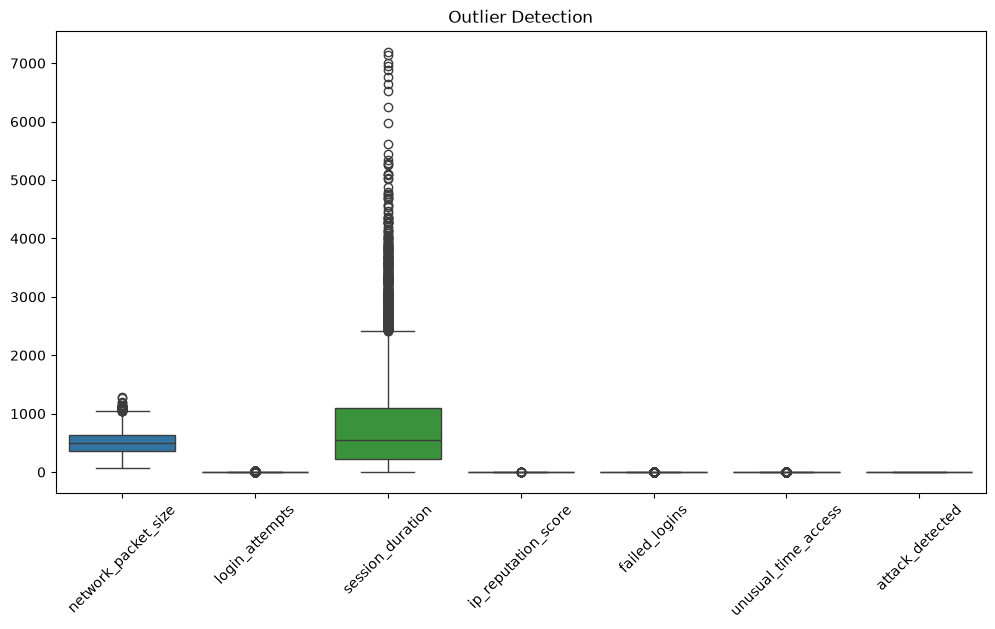

In [33]:
plt.figure(figsize=(12,6))

sns.boxplot(data=df.select_dtypes(include='number'))

plt.xticks(rotation=45)
plt.title("Outlier Detection")
plt.show()

# Outlier Detection using IQR Method

In [34]:
num_cols = [
    'network_packet_size',
    'login_attempts',
    'session_duration',
    'ip_reputation_score',
    'failed_logins'
]

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col, ":", len(outliers))

network_packet_size : 37
login_attempts : 206
session_duration : 418
ip_reputation_score : 21
failed_logins : 323


# Train-Test Split

In [35]:
X = df.drop(columns=['attack_detected', 'session_id'])
y = df['attack_detected']

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (7629, 9)
X_test: (1908, 9)
y_train: (7629,)
y_test: (1908,)


* Missing Values Handling

In [36]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='most_frequent')

X_train[['encryption_used']] = imputer.fit_transform(
    X_train[['encryption_used']]
)

X_test[['encryption_used']] = imputer.transform(
    X_test[['encryption_used']]
)
print("Training missing values:")
print(X_train.isnull().sum())
print("\nTesting missing values:")
print(X_test.isnull().sum())

Training missing values:
network_packet_size    0
protocol_type          0
login_attempts         0
session_duration       0
encryption_used        0
ip_reputation_score    0
failed_logins          0
browser_type           0
unusual_time_access    0
dtype: int64

Testing missing values:
network_packet_size    0
protocol_type          0
login_attempts         0
session_duration       0
encryption_used        0
ip_reputation_score    0
failed_logins          0
browser_type           0
unusual_time_access    0
dtype: int64


* Categorical columns
     * protocol_type
     * encryption_used
     * browser_type


* Feature Scaling

In [38]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

# Numerical columns
num_cols = [
    'network_packet_size',
    'login_attempts',
    'session_duration',
    'ip_reputation_score',
    'failed_logins'
]

# Categorical columns
cat_cols = [
    'protocol_type',
    'encryption_used',
    'browser_type'
]

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ],
    remainder='passthrough'
)

# Fit only on training data
X_train_scaled = preprocessor.fit_transform(X_train)

# Apply same transformation to test data
X_test_scaled = preprocessor.transform(X_test)

print("X_train shape:", X_train_scaled.shape)
print("X_test shape:", X_test_scaled.shape)

X_train shape: (7629, 16)
X_test shape: (1908, 16)


# EDA – Exploratory Data Analysis

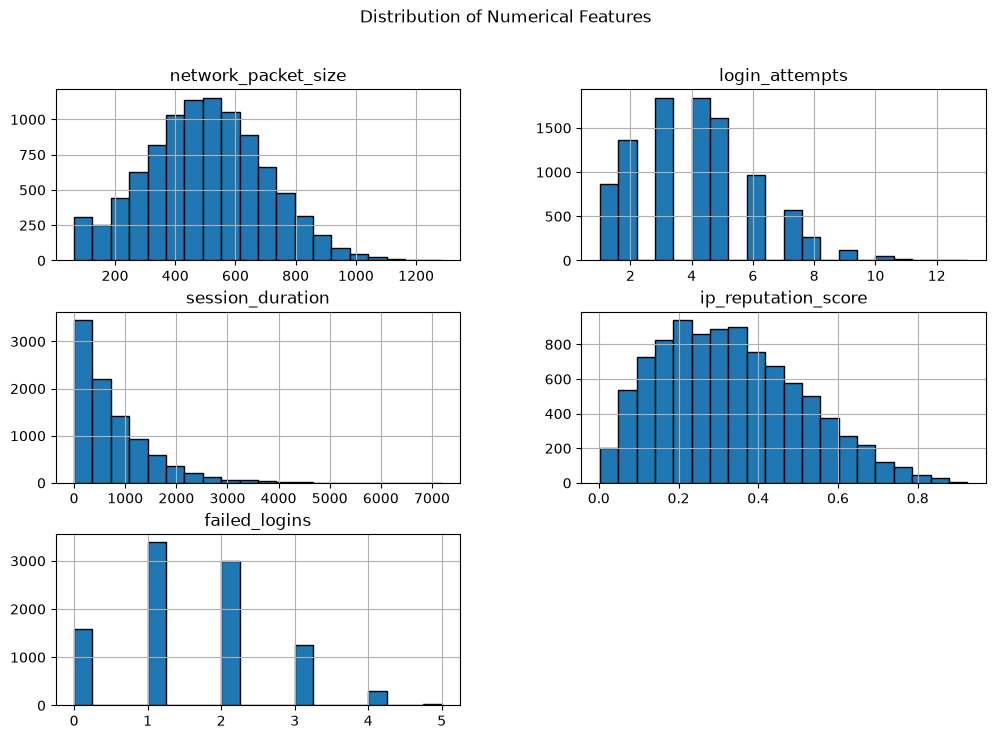

In [41]:
num_cols = [
    'network_packet_size',
    'login_attempts',
    'session_duration',
    'ip_reputation_score',
    'failed_logins'
]

df[num_cols].hist(figsize=(12, 8), bins=20, edgecolor='black')

plt.suptitle("Distribution of Numerical Features")
plt.show()

* Outlier Visualization Using Boxplots

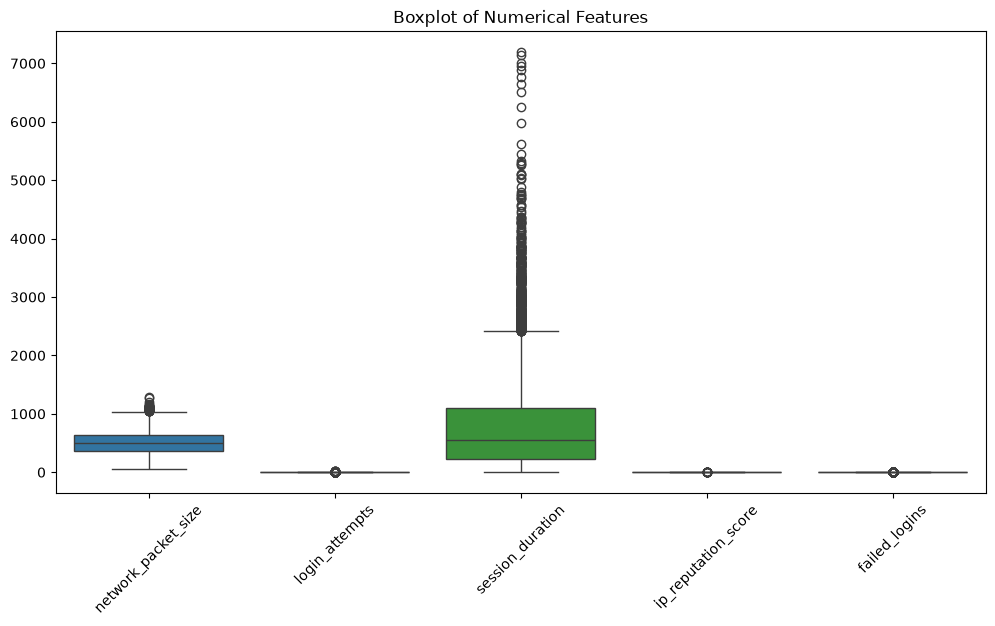

In [42]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=df[num_cols])

plt.title("Boxplot of Numerical Features")
plt.xticks(rotation=45)
plt.show()

* Categorical Feature Analysis

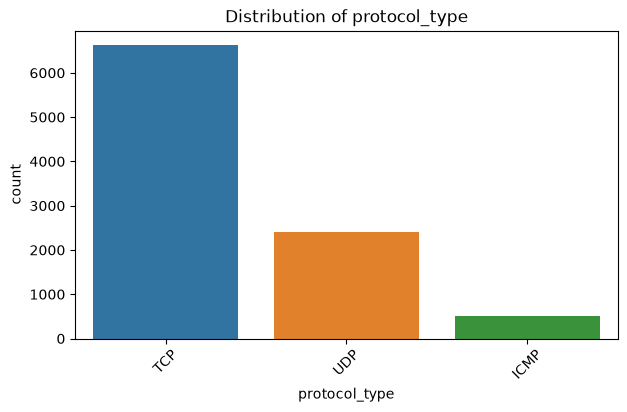

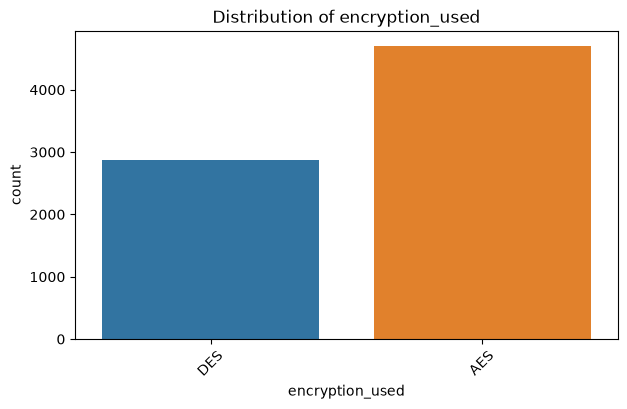

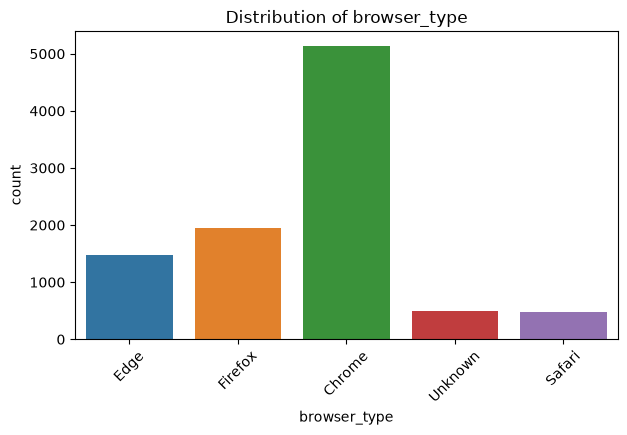

In [43]:
cat_cols = ['protocol_type', 'encryption_used', 'browser_type']

for col in cat_cols:
    plt.figure(figsize=(7, 4))
    sns.countplot(data=df, x=col, hue=col, legend=False)
    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=45)
    plt.show()

# Correlation Heatmap

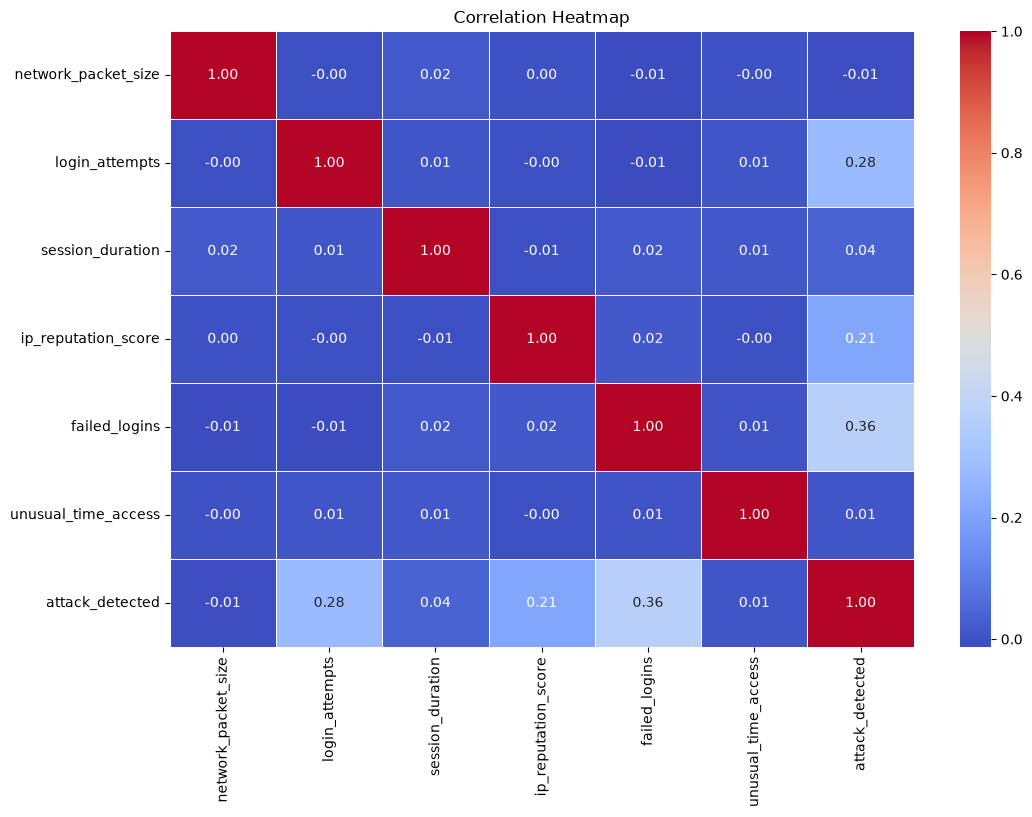

In [44]:
plt.figure(figsize=(12, 8))

correlation = df.select_dtypes(include='number').corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.show()

#  APPLY CLASSIFICATION ALGORITHMS

* Logistic Regression

In [49]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score

lr_model = LogisticRegression(max_iter=1000)

# Training
lr_model.fit(X_train_scaled, y_train)

# Predictions
y_train_pred = lr_model.predict(X_train_scaled)
y_test_pred = lr_model.predict(X_test_scaled)

# Accuracy
lr_train_acc = accuracy_score(y_train, y_train_pred)
lr_test_acc = accuracy_score(y_test, y_test_pred)

# Cross Validation
lr_cv = cross_val_score(
    lr_model,
    X_train_scaled,
    y_train,
    cv=5,
    scoring='accuracy'
)
print("Logistic Regression Train Accuracy:", lr_train_acc * 100)
print("Logistic Regression Test Accuracy:", lr_test_acc * 100)
print("Logistic Regression CV Scores:", lr_cv)
print("Logistic Regression Mean CV Score:", lr_cv.mean() * 100)


Logistic Regression Train Accuracy: 74.34788307772972
Logistic Regression Test Accuracy: 72.9035639412998
Logistic Regression CV Scores: [0.74836173 0.74770642 0.72477064 0.74705111 0.73245902]
Logistic Regression Mean CV Score: 74.00697849300646


In [47]:
train_score = lr_model.score(X_train_scaled, y_train)
test_score = lr_model.score(X_test_scaled, y_test)

print("Train Score:", train_score)
print("Test Score:", test_score)

Train Score: 0.7434788307772972
Test Score: 0.7290356394129979


* Nearest Neighbors (KNN)

In [50]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

# Create Model
knn_model = KNeighborsClassifier(n_neighbors=5)

# Training
knn_model.fit(X_train_scaled, y_train)

# Predictions
y_train_pred = knn_model.predict(X_train_scaled)
y_test_pred = knn_model.predict(X_test_scaled)

# Train and Test Accuracy
knn_train_acc = accuracy_score(y_train, y_train_pred)
knn_test_acc = accuracy_score(y_test, y_test_pred)

# Cross Validation
knn_cv = cross_val_score(
    knn_model,
    X_train_scaled,
    y_train,
    cv=5,
    scoring='accuracy'
)

print("KNN Train Accuracy:", knn_train_acc * 100)
print("KNN Test Accuracy:", knn_test_acc * 100)
print("KNN CV Scores:", knn_cv)
print("KNN Mean CV Score:", knn_cv.mean() * 100)

KNN Train Accuracy: 87.28535850045877
KNN Test Accuracy: 80.9748427672956
KNN CV Scores: [0.81913499 0.81323722 0.81258191 0.81913499 0.80852459]
KNN Mean CV Score: 81.45227424102444


* Decision Tree Classifier

In [52]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

# Create Model
dt_model = DecisionTreeClassifier(random_state=42)

# Training
dt_model.fit(X_train_scaled, y_train)

# Predictions
y_train_pred = dt_model.predict(X_train_scaled)
y_test_pred = dt_model.predict(X_test_scaled)

# Train and Test Accuracy
dt_train_acc = accuracy_score(y_train, y_train_pred)
dt_test_acc = accuracy_score(y_test, y_test_pred)

# Cross Validation
dt_cv = cross_val_score(
    dt_model,
    X_train_scaled,
    y_train,
    cv=5,
    scoring='accuracy'
)

print("Decision Tree Train Accuracy:", dt_train_acc * 100)
print("Decision Tree Test Accuracy:", dt_test_acc * 100)
print("Decision Tree CV Scores:", dt_cv)
print("Decision Tree Mean CV Score:", dt_cv.mean() * 100)

Decision Tree Train Accuracy: 100.0
Decision Tree Test Accuracy: 82.0230607966457
Decision Tree CV Scores: [0.83027523 0.81323722 0.80996068 0.80733945 0.80983607]
Decision Tree Mean CV Score: 81.41297294974541


* Random Forest Classifier

In [53]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

# Create Model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Training
rf_model.fit(X_train_scaled, y_train)

# Predictions
y_train_pred = rf_model.predict(X_train_scaled)
y_test_pred = rf_model.predict(X_test_scaled)

# Accuracy
rf_train_acc = accuracy_score(y_train, y_train_pred)
rf_test_acc = accuracy_score(y_test, y_test_pred)

# Cross Validation
rf_cv = cross_val_score(
    rf_model,
    X_train_scaled,
    y_train,
    cv=5,
    scoring='accuracy'
)

print("Random Forest Train Accuracy:", rf_train_acc * 100)
print("Random Forest Test Accuracy:", rf_test_acc * 100)
print("Random Forest CV Scores:", rf_cv)
print("Random Forest Mean CV Score:", rf_cv.mean() * 100)

Random Forest Train Accuracy: 100.0
Random Forest Test Accuracy: 88.36477987421384
Random Forest CV Scores: [0.89777195 0.88859764 0.89515072 0.90039318 0.88393443]
Random Forest Mean CV Score: 89.31695851148402


* Support Vector Machine (SVM)

In [54]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

# Create Model
svm_model = SVC()

# Training
svm_model.fit(X_train_scaled, y_train)

# Predictions
y_train_pred = svm_model.predict(X_train_scaled)
y_test_pred = svm_model.predict(X_test_scaled)

# Accuracy
svm_train_acc = accuracy_score(y_train, y_train_pred)
svm_test_acc = accuracy_score(y_test, y_test_pred)

# Cross Validation
svm_cv = cross_val_score(
    svm_model,
    X_train_scaled,
    y_train,
    cv=5,
    scoring='accuracy'
)

print("SVM Train Accuracy:", svm_train_acc * 100)
print("SVM Test Accuracy:", svm_test_acc * 100)
print("SVM CV Scores:", svm_cv)
print("SVM Mean CV Score:", svm_cv.mean() * 100)

SVM Train Accuracy: 89.18600078647268
SVM Test Accuracy: 87.26415094339622
SVM CV Scores: [0.88663172 0.87549148 0.88597641 0.88204456 0.87016393]
SVM Mean CV Score: 88.00616204370154


* AdaBoost Classifier

In [55]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

ada_model = AdaBoostClassifier(n_estimators=100, random_state=42)

ada_model.fit(X_train_scaled, y_train)

y_train_pred = ada_model.predict(X_train_scaled)
y_test_pred = ada_model.predict(X_test_scaled)

ada_train_acc = accuracy_score(y_train, y_train_pred)
ada_test_acc = accuracy_score(y_test, y_test_pred)

ada_cv = cross_val_score(
    ada_model,
    X_train_scaled,
    y_train,
    cv=5,
    scoring='accuracy'
)

print("AdaBoost Train Accuracy:", ada_train_acc * 100)
print("AdaBoost Test Accuracy:", ada_test_acc * 100)
print("AdaBoost CV Scores:", ada_cv)
print("AdaBoost Mean CV Score:", ada_cv.mean() * 100)

AdaBoost Train Accuracy: 87.37711364530082
AdaBoost Test Accuracy: 86.42557651991615
AdaBoost CV Scores: [0.88204456 0.87483617 0.87090433 0.87549148 0.86491803]
AdaBoost Mean CV Score: 87.36389145521345


* model comparison graph

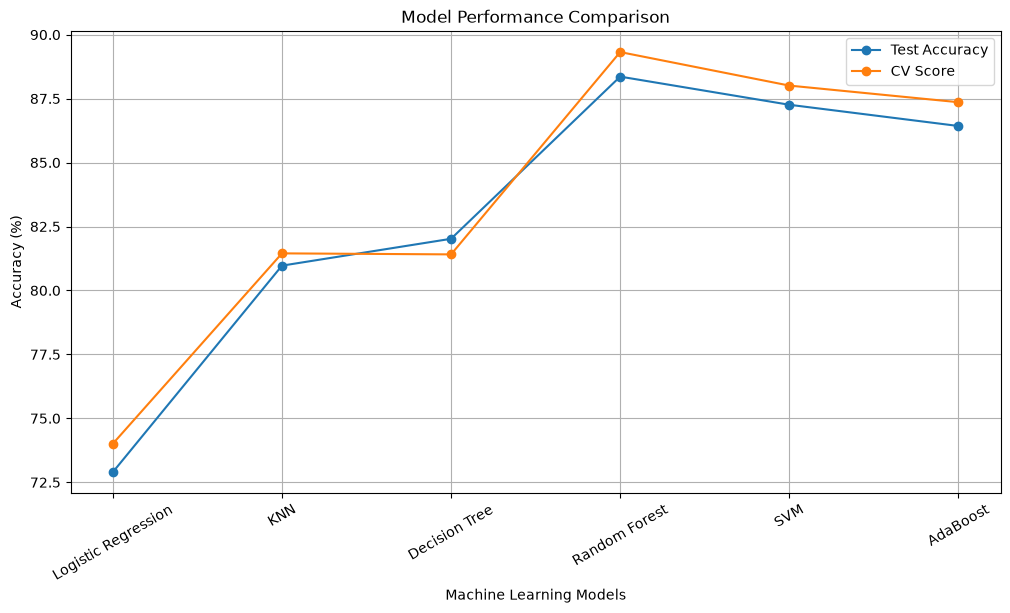

In [56]:
# 6.8 Model Comparison Graph

import matplotlib.pyplot as plt

models = [
    'Logistic Regression',
    'KNN',
    'Decision Tree',
    'Random Forest',
    'SVM',
    'AdaBoost'
]

test_accuracies = [
    72.90, 80.97, 82.02, 88.36, 87.26, 86.43
]

cv_scores = [
    74.01, 81.45, 81.41, 89.32, 88.01, 87.36
]

plt.figure(figsize=(12, 6))

plt.plot(models, test_accuracies, marker='o', label='Test Accuracy')
plt.plot(models, cv_scores, marker='o', label='CV Score')

plt.title('Model Performance Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Accuracy (%)')
plt.xticks(rotation=30)
plt.legend()
plt.grid(True)
plt.show()

* confusion matrixs-random forest

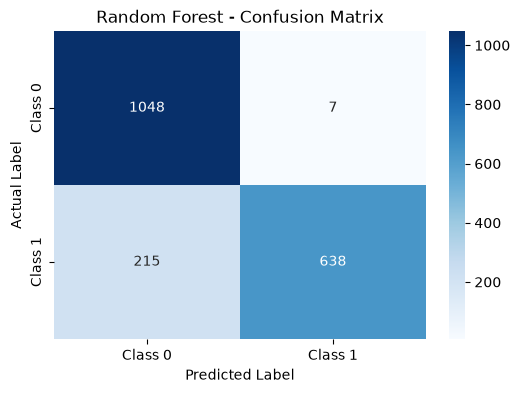

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.99      0.90      1055
           1       0.99      0.75      0.85       853

    accuracy                           0.88      1908
   macro avg       0.91      0.87      0.88      1908
weighted avg       0.90      0.88      0.88      1908



In [57]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Predictions
y_pred = rf_model.predict(X_test_scaled)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Class 0', 'Class 1'],
    yticklabels=['Class 0', 'Class 1']
)

plt.title('Random Forest - Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

# Classification Report
print("Classification Report:")
print(classification_report(y_test, y_pred))

* ROC Curve and ROC-AUC Score

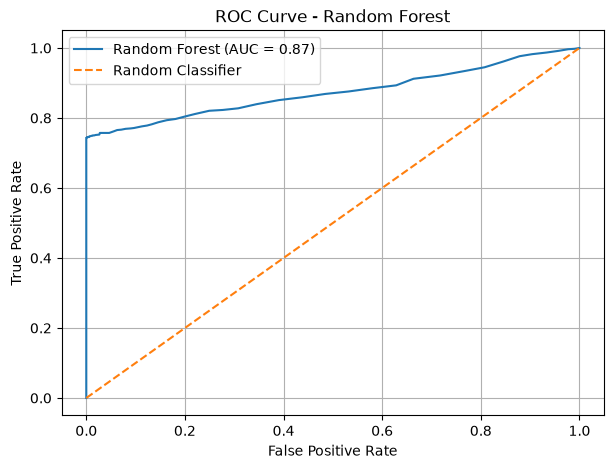

Random Forest ROC-AUC Score: 0.8735274998194275


In [58]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Probability predictions
y_prob = rf_model.predict_proba(X_test_scaled)[:, 1]

# ROC values
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# AUC Score
auc_score = roc_auc_score(y_test, y_prob)

# Plot ROC Curve
plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f'Random Forest (AUC = {auc_score:.2f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Random Forest')
plt.legend()
plt.grid()
plt.show()

print("Random Forest ROC-AUC Score:", auc_score)

* Final Model Comparison

In [ ]:
import pandas as pd

results = {
    'Model': [
        'Logistic Regression',
        'KNN',
        'Decision Tree',
        'Random Forest',
        'SVM',
        'AdaBoost'
    ],
    'Train Accuracy': [
        74.35, 87.29, 100.00, 100.00, 89.19, 87.38
    ],
    'Test Accuracy': [
        72.90, 80.97, 82.02, 88.36, 87.26, 86.43
    ],
    'CV Score': [
        74.01, 81.45, 81.41, 89.32, 88.01, 87.36
    ]
}

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by='Test Accuracy',
    ascending=False
)

print(comparison_df)

                 Model  Train Accuracy  Test Accuracy  CV Score
3        Random Forest          100.00          88.36     89.32
4                  SVM           89.19          87.26     88.01
5             AdaBoost           87.38          86.43     87.36
2        Decision Tree          100.00          82.02     81.41
1                  KNN           87.29          80.97     81.45
0  Logistic Regression           74.35          72.90     74.01


In [61]:
# 8.1 Hyperparameter Tuning

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

rf = RandomForestClassifier(random_state=42)

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_scaled, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Score:", grid_search.best_score_ * 100)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Parameters: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}
Best CV Score: 89.6184259716821
